In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

flights = pd.read_csv("data/flights.csv")
airports = pd.read_csv("data/airports.csv")

In [3]:
display(flights.head())
display(airports.head())

,date,delay,distance,origin,destination
0,2001-01-01,66,1750,DTW,LAS
1,2001-01-01,95,2399,HNL,SFO
2,2001-01-01,-5,407,LAS,OAK
3,2001-01-01,4,256,LAS,PHX
4,2001-01-01,-6,377,MHT,BWI


,iata,name,city,state,country,latitude,longitude
0,00M,Thigpen,Bay Springs,MS,USA,31.953765,-89.234505
1,00R,Livingston Municipal,Livingston,TX,USA,30.685861,-95.017928
2,00V,Meadow Lake,Colorado Springs,CO,USA,38.945749,-104.569893
3,01G,Perry-Warsaw,Perry,NY,USA,42.741347,-78.052081
4,01J,Hilliard Airpark,Hilliard,FL,USA,30.688012,-81.905944


In [4]:
print("Flights:", flights.shape)
print("Airports:", airports.shape)

Flights: (20000, 5)
Airports: (3376, 7)


In [5]:
flights.info()
airports.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   date         20000 non-null  str  
 1   delay        20000 non-null  int64
 2   distance     20000 non-null  int64
 3   origin       20000 non-null  str  
 4   destination  20000 non-null  str  
dtypes: int64(2), str(3)
memory usage: 781.4 KB
<class 'pandas.DataFrame'>
RangeIndex: 3376 entries, 0 to 3375
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   iata       3376 non-null   str    
 1   name       3376 non-null   str    
 2   city       3364 non-null   str    
 3   state      3364 non-null   str    
 4   country    3376 non-null   str    
 5   latitude   3376 non-null   float64
 6   longitude  3376 non-null   float64
dtypes: float64(2), str(5)
memory usage: 184.8 KB


In [6]:
print(flights.columns)
print(airports.columns)

Index(['date', 'delay', 'distance', 'origin', 'destination'], dtype='str')
Index(['iata', 'name', 'city', 'state', 'country', 'latitude', 'longitude'], dtype='str')


In [ ]:
## 1. Read and understand the data

## Each row in the flights dataset represents a flight record.

## The main columns used in this analysis are date, delay,
## distance, origin and destination.

## The airports dataset provides additional information
## about airport names, cities, states and countries.

In [ ]:
#Part 2 – Clean the data

In [8]:
flights_raw = flights.copy()
airports_raw = airports.copy()

In [10]:
print("Before:", flights["date"].dtype)

flights["date"] = pd.to_datetime(
    flights["date"], errors="coerce"
)

print("After:", flights["date"].dtype)
print("Rows processed:", len(flights))
print("Invalid dates:", flights["date"].isna().sum())

Before: str
After: datetime64[us]
Rows processed: 20000
Invalid dates: 0


In [11]:
duplicate_count = flights.duplicated().sum()

print("Duplicate records:", duplicate_count)

display(
    flights[flights.duplicated(keep=False)]
)

Duplicate records: 28


,date,delay,distance,origin,destination
541,2001-01-03,19,543,PDX,OAK
626,2001-01-03,19,543,PDX,OAK
768,2001-01-04,-18,606,ORD,ATL
898,2001-01-04,-18,606,ORD,ATL
1596,2001-01-08,5,410,STL,CMH
1705,2001-01-08,5,410,STL,CMH
1843,2001-01-09,3,641,DFW,DEN
2016,2001-01-09,3,641,DFW,DEN
2053,2001-01-10,-8,1123,DEN,DTW
2101,2001-01-10,-8,1123,DEN,DTW


In [12]:
duplicate_airports = airports[
    airports.duplicated(subset="iata", keep=False)
]

display(duplicate_airports)

,iata,name,city,state,country,latitude,longitude
47,0.00E+00,Moriarty,Moriarty,NM,USA,34.985606,-106.009466
48,0.00E+00,Crownpoint,Crownpoint,NM,USA,35.717659,-108.201596


In [13]:
invalid_distance = flights["distance"] <= 0

print("Invalid distances:", invalid_distance.sum())

display(flights[invalid_distance])

Invalid distances: 0


,date,delay,distance,origin,destination


In [14]:
for column in ["origin", "destination"]:

    cleaned = flights[column].str.strip().str.upper()

    print(column, "affected rows:",
          (flights[column] != cleaned).sum())

    flights[column] = cleaned

origin affected rows: 0
destination affected rows: 0


In [15]:
invalid_codes = ~airports["iata"].str.fullmatch(
    r"[A-Z0-9]{3,4}", na=False
)

display(airports[invalid_codes])

print("Invalid airport codes:", invalid_codes.sum())

airports = airports.loc[~invalid_codes].copy()

print("Remaining airports:", len(airports))

,iata,name,city,state,country,latitude,longitude
47,0.00E+00,Moriarty,Moriarty,NM,USA,34.985606,-106.009466
48,0.00E+00,Crownpoint,Crownpoint,NM,USA,35.717659,-108.201596


Invalid airport codes: 2
Remaining airports: 3374


In [16]:
cleaned_names = airports["name"].str.replace(
    r"\s+", " ", regex=True
).str.strip()

print("Affected rows:",
      (airports["name"] != cleaned_names).sum())

airports["name"] = cleaned_names

Affected rows: 12


#Part 3 – Handle missing values

In [17]:
print("Missing values in flights:")
print(flights.isnull().sum())

print("Missing values in airports:")
print(airports.isnull().sum())

Missing values in flights:
date           0
delay          0
distance       0
origin         0
destination    0
dtype: int64
Missing values in airports:
iata          0
name          0
city         12
state        12
country       0
latitude      0
longitude     0
dtype: int64


In [18]:
print(flights.isnull().mean() * 100)

print(airports.isnull().mean() * 100)

date           0.0
delay          0.0
distance       0.0
origin         0.0
destination    0.0
dtype: float64
iata         0.000000
name         0.000000
city         0.355661
state        0.355661
country      0.000000
latitude     0.000000
longitude    0.000000
dtype: float64


In [20]:
print("Missing city:", airports["city"].isna().sum())
print("Missing state:", airports["state"].isna().sum())

airports["city"] = airports["city"].fillna("Unknown")
airports["state"] = airports["state"].fillna("Unknown")

Missing city: 12
Missing state: 12


In [21]:
print(airports.isnull().sum())

iata         0
name         0
city         0
state        0
country      0
latitude     0
longitude    0
dtype: int64


#### Missing value decisions

City:
Missing city values were replaced with "Unknown"
because the correct city cannot be determined
from the available information.

State:
Missing state values were replaced with "Unknown"
to preserve airport records without inventing locations.

Missing information may indicate unavailable or
unrecorded geographical details.

In [22]:
#Part 4 – Merge with the second table
#Merge the flights dataset with the airports dataset using origin and iata.
before_merge = len(flights)

flights = flights.merge(
    airports,
    left_on="origin",
    right_on="iata",
    how="left",
    validate="many_to_one",
    indicator=True
)

after_merge = len(flights)

In [23]:
#Validate the merge
print("Before merge:", before_merge)
print("After merge:", after_merge)
print("Difference:", after_merge - before_merge)

print(flights["_merge"].value_counts())

assert before_merge == after_merge

Before merge: 20000
After merge: 20000
Difference: 0
_merge
both          20000
left_only         0
right_only        0
Name: count, dtype: int64


In [24]:
flights = flights.drop(columns=["_merge"])

display(flights.head())

,date,delay,distance,origin,destination,iata,name,city,state,country,latitude,longitude
0,2001-01-01,66,1750,DTW,LAS,DTW,Detroit Metropolitan-Wayne County,Detroit,MI,USA,42.212059,-83.348836
1,2001-01-01,95,2399,HNL,SFO,HNL,Honolulu International,Honolulu,HI,USA,21.318691,-157.922407
2,2001-01-01,-5,407,LAS,OAK,LAS,McCarran International,Las Vegas,NV,USA,36.080361,-115.152333
3,2001-01-01,4,256,LAS,PHX,LAS,McCarran International,Las Vegas,NV,USA,36.080361,-115.152333
4,2001-01-01,-6,377,MHT,BWI,MHT,Manchester,Manchester,NH,USA,42.934516,-71.437056


##Part 5 – Create new columns

In [25]:
#Weekday
flights["weekday"] = flights["date"].dt.day_name()

In [26]:
flights["month"] = flights["date"].dt.month_name()

In [27]:
flights["delay_status"] = np.where(
    flights["delay"] > 0,
    "Delayed",
    "Not delayed"
)

In [28]:
flights[[
    "date",
    "weekday",
    "month",
    "delay",
    "delay_status"
]].head(10)

,date,weekday,month,delay,delay_status
0,2001-01-01,Monday,January,66,Delayed
1,2001-01-01,Monday,January,95,Delayed
2,2001-01-01,Monday,January,-5,Not delayed
3,2001-01-01,Monday,January,4,Delayed
4,2001-01-01,Monday,January,-6,Not delayed
5,2001-01-01,Monday,January,-27,Not delayed
6,2001-01-01,Monday,January,-7,Not delayed
7,2001-01-01,Monday,January,-26,Not delayed
8,2001-01-01,Monday,January,29,Delayed
9,2001-01-01,Monday,January,-4,Not delayed


##Part 6 – Group and compare

In [29]:
airport_summary = flights.groupby(
    ["origin", "name"]
).agg(
    average_delay=("delay", "mean"),
    median_delay=("delay", "median"),
    flight_count=("delay", "count")
)

airport_summary = airport_summary.round(2)

display(airport_summary.head(10))

,,average_delay,median_delay,flight_count
origin,name,,,
ABE,Lehigh Valley International,-5.00,-5.5,8
ABI,Abilene Regional,0.40,0.0,5
ABQ,Albuquerque International,8.35,0.0,123
ACT,Waco Regional,3.83,0.5,6
ALB,Albany Cty,2.70,-5.5,54
AMA,Amarillo International,2.90,-1.0,21
ANC,Ted Stevens Anchorage International,11.83,6.5,58
APF,Naples Municipal,-9.00,-9.0,1
ATL,William B Hartsfield-Atlanta Intl,7.81,0.0,846


In [30]:
#Average delay by weekday
weekday_summary = flights.groupby("weekday").agg(
    average_delay=("delay", "mean"),
    median_delay=("delay", "median"),
    flight_count=("delay", "count")
)

display(weekday_summary.round(2))

,average_delay,median_delay,flight_count
weekday,,,
Friday,11.76,3.0,3003
Monday,7.07,-1.0,2952
Saturday,4.21,-2.0,2655
Sunday,6.97,-1.0,2648
Thursday,9.30,1.0,2944
Tuesday,7.18,0.0,2903
Wednesday,6.91,0.0,2895


In [31]:
#Average delay by month
monthly_summary = flights.groupby("month").agg(
    average_delay=("delay", "mean"),
    flight_count=("delay", "count")
)

display(monthly_summary.round(2))

,average_delay,flight_count
month,,
February,9.60,5964
January,6.44,6937
March,7.35,7099


#Part 7 – Describe with numbers

In [32]:
#Descriptive statistics
flights["delay"].describe()

count    20000.000000
mean         7.703900
std         31.318537
min        -59.000000
25%         -8.000000
50%          0.000000
75%         13.000000
max        522.000000
Name: delay, dtype: float64

In [33]:
#Middle and spread
print("Mean:", flights["delay"].mean())
print("Median:", flights["delay"].median())
print("Standard deviation:", flights["delay"].std())
print("Minimum:", flights["delay"].min())
print("Maximum:", flights["delay"].max())
print("Range:", flights["delay"].max()
      - flights["delay"].min())

Mean: 7.7039
Median: 0.0
Standard deviation: 31.318537119865073
Minimum: -59
Maximum: 522
Range: 581


In [34]:
#Outlier investigation
Q1 = flights["delay"].quantile(0.25)
Q3 = flights["delay"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = flights[
    (flights["delay"] < lower_bound) |
    (flights["delay"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Total outliers:", len(outliers))

Q1: -8.0
Q3: 13.0
IQR: 21.0
Lower bound: -39.5
Upper bound: 44.5
Total outliers: 1703


In [35]:
#Compare distance and delay
correlation = flights["distance"].corr(
    flights["delay"]
)

print("Correlation:", round(correlation, 3))

Correlation: -0.022


#Part 8 – Data visualisation

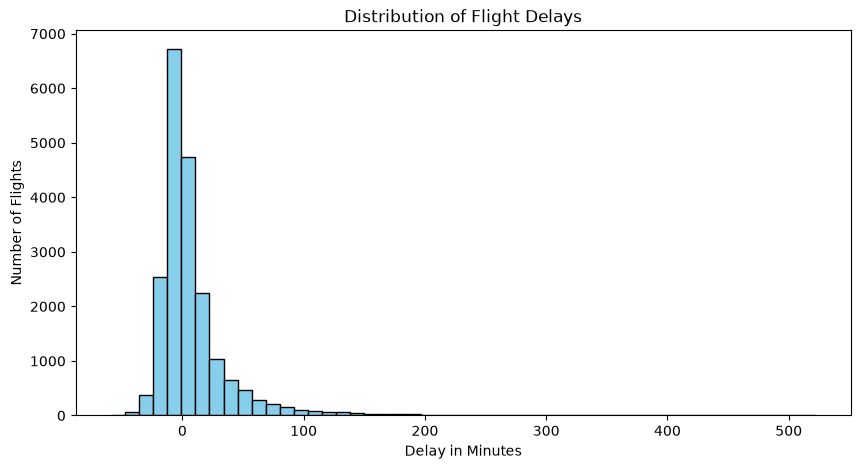

In [36]:
plt.figure(figsize=(10, 5))

plt.hist(
    flights["delay"],
    bins=50,
    color="skyblue",
    edgecolor="black"
)

plt.title("Distribution of Flight Delays")
plt.xlabel("Delay in Minutes")
plt.ylabel("Number of Flights")
plt.show()